# A/B-тест: анализ эксперимента и проверка методики

Учебный кейс по анализу A/B-теста: дизайн, проверка SRM, первичная и вторичная метрики, guardrail, сегменты и итоговое решение.

Данные синтетические и сгенерированы с известным эффектом (`scripts/generate_data.py`, seed=42). Это позволяет не только показать расчёты, но и проверить, что методика находит заложенный эффект и не находит несуществующий.

## 1. Дизайн эксперимента

**Продуктовая гипотеза:** новый вариант страницы оплаты повышает конверсию в покупку.

**Метрики:**

| Роль | Метрика | Определение |
|---|---|---|
| Первичная | Конверсия | доля пользователей с покупкой |
| Вторичная | ARPU | выручка на пользователя, включая нули |
| Guardrail | Доля возвратов | не должна вырасти |

**Статистические гипотезы:**

- H₀: конверсия в группах одинакова, `p_treatment = p_control`;
- H₁: конверсия в treatment отличается, `p_treatment ≠ p_control`.

Уровень значимости α = 0.05 (двусторонний), мощность 1 − β = 0.80, минимальный детектируемый эффект MDE = 1 п.п. при базовой конверсии 8 %.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 13,
                     'axes.titleweight': 'bold', 'axes.unicode_minus': False})
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

ALPHA = 0.05
POWER = 0.80
P_BASE = 0.08
MDE = 0.01
RNG = np.random.default_rng(42)

In [2]:
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_beta = stats.norm.ppf(POWER)
p_alt = P_BASE + MDE

n_per_group = ((z_alpha + z_beta) ** 2 * (P_BASE * (1 - P_BASE) + p_alt * (1 - p_alt))) / MDE ** 2
print(f'Требуемый размер группы: {n_per_group:,.0f} пользователей')
print(f'Всего на две группы: {2 * n_per_group:,.0f}')

Требуемый размер группы: 12,205 пользователей
Всего на две группы: 24,410


Для MDE в 1 п.п. при базовой конверсии 8 % нужно около 12 200 пользователей на группу. В эксперименте участвовало 12 300 на группу — с запасом на округление.

## 2. Данные и проверка SRM

In [3]:
df = pd.read_csv('data/experiment.csv')
df['converted'] = df['converted'].astype(int)
df['refunded'] = df['refunded'].astype(int)

print(f'строк: {len(df):,}; колонки: {list(df.columns)}')
display(df.head())
display(df.groupby(['group', 'device']).size().unstack())

строк: 24,600; колонки: ['user_id', 'group', 'device', 'converted', 'revenue', 'refunded']


,user_id,group,device,converted,revenue,refunded
0,u000001,control,desktop,1,"1,218.7000",0
1,u000002,control,mobile,1,596.8500,0
2,u000003,control,mobile,0,0.0000,0
3,u000004,control,mobile,0,0.0000,0
4,u000005,control,desktop,0,0.0000,0


device,desktop,mobile
group,,
control,4695,7605
treatment,4631,7669


In [4]:
counts = df['group'].value_counts()
total = counts.sum()
chi2, p_srm = stats.chisquare(counts.values, f_exp=[total / 2, total / 2])
print(f'SRM: control = {counts["control"]:,}, treatment = {counts["treatment"]:,}')
print(f'chi2 = {chi2:.3f}, p = {p_srm:.3f}')

print('\nSRM по устройствам:')
for device, subset in df.groupby('device'):
    c = subset['group'].value_counts()
    chi2_dev, p_dev = stats.chisquare(c.values, f_exp=[c.sum() / 2, c.sum() / 2])
    print(f'  {device}: {c["control"]:,} / {c["treatment"]:,}, p = {p_dev:.3f}')

SRM: control = 12,300, treatment = 12,300
chi2 = 0.000, p = 1.000

SRM по устройствам:
  desktop: 4,695 / 4,631, p = 0.508
  mobile: 7,605 / 7,669, p = 0.605


SRM (sample ratio mismatch) проверяет, совпадает ли фактическое разделение с ожидаемым 50/50. p > 0.05 — перекосов нет, данные можно анализировать. Проверка отдельно по устройствам нужна потому, что расхождение внутри сегмента могло бы исказить сегментный анализ.

## 3. Первичная метрика: конверсия

In [5]:
summary = (df.groupby('group')['converted']
           .agg(users='size', conversions='sum', conversion='mean'))
display(summary)

p_c = summary.loc['control', 'conversion']
p_t = summary.loc['treatment', 'conversion']
n_c = summary.loc['control', 'users']
n_t = summary.loc['treatment', 'users']

diff = p_t - p_c
se = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
z_stat = diff / se
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
ci_low, ci_high = diff - z_alpha * se, diff + z_alpha * se

print(f'control:   {p_c:.2%}')
print(f'treatment: {p_t:.2%}')
print(f'разница:   {diff * 100:+.2f} п.п. (относительный рост {diff / p_c:+.1%})')
print(f'95 % ДИ:   [{ci_low * 100:+.2f}; {ci_high * 100:+.2f}] п.п.')
print(f'z = {z_stat:.2f}, p = {p_value:.2e}')

,users,conversions,conversion
group,,,
control,12300,984,0.0800
treatment,12300,1160,0.0943


control:   8.00%
treatment: 9.43%
разница:   +1.43 п.п. (относительный рост +17.9%)
95 % ДИ:   [+0.73; +2.14] п.п.
z = 3.98, p = 6.90e-05


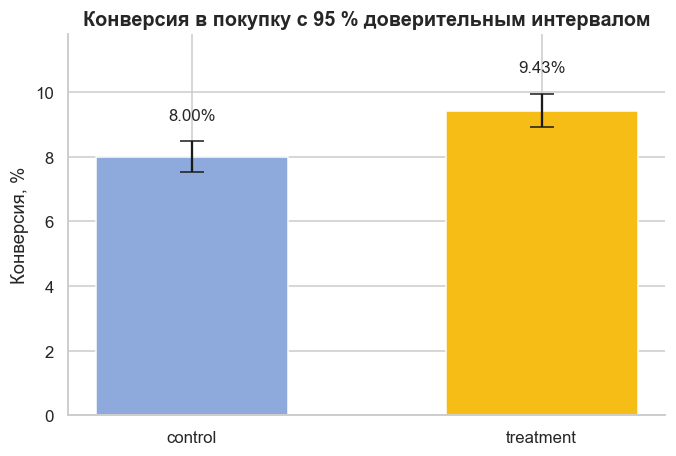

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
groups = summary.index
values = summary['conversion'] * 100
errors = [z_alpha * np.sqrt(p * (1 - p) / n) * 100 for p, n in
          zip(summary['conversion'], summary['users'])]
bars = ax.bar(groups, values, yerr=errors, capsize=8, color=['#8EA9DB', '#F6BD16'], width=0.55)
ax.bar_label(bars, fmt='%.2f%%', padding=12, fontsize=11)
ax.set(title='Конверсия в покупку с 95 % доверительным интервалом', ylabel='Конверсия, %', xlabel='')
ax.set_ylim(0, max(values) * 1.25)
sns.despine()
plt.show()

Разница статистически значима: конверсия выросла на 1.4 п.п. (относительный рост около 18 %), доверительный интервал не включает ноль. Направление и величина совпадают с заложенным в данные эффектом.

## 4. Вторичная метрика: ARPU

In [7]:
arpu = df.groupby('group')['revenue'].agg(['mean', 'median', 'std', 'count'])
display(arpu)

rev_c = df.loc[df['group'] == 'control', 'revenue'].to_numpy()
rev_t = df.loc[df['group'] == 'treatment', 'revenue'].to_numpy()
arpu_diff = rev_t.mean() - rev_c.mean()

u_stat, p_mw = stats.mannwhitneyu(rev_t, rev_c, alternative='two-sided')
print(f'ARPU: control {rev_c.mean():,.2f} ₽, treatment {rev_t.mean():,.2f} ₽')
print(f'разница: {arpu_diff:+,.2f} ₽ ({arpu_diff / rev_c.mean():+.1%})')
print(f'Манн—Уитни: U = {u_stat:,.0f}, p = {p_mw:.2e}')

converted_mean = df[df['converted'] == 1].groupby('group')['revenue'].mean()
print(f'средний чек купивших: control {converted_mean["control"]:,.2f} ₽, '
      f'treatment {converted_mean["treatment"]:,.2f} ₽ '
      f'({converted_mean["treatment"] / converted_mean["control"] - 1:+.1%})')

,mean,median,std,count
group,,,,
control,141.3836,0.0000,693.4976,12300
treatment,172.2491,0.0000,735.0129,12300


ARPU: control 141.38 ₽, treatment 172.25 ₽
разница: +30.87 ₽ (+21.8%)
Манн—Уитни: U = 76,729,641, p = 6.86e-05
средний чек купивших: control 1,767.29 ₽, treatment 1,826.43 ₽ (+3.3%)


In [8]:
def bootstrap_mean_diff(a, b, iterations=2000, seed=42):
    rng = np.random.default_rng(seed)
    diffs = np.empty(iterations)
    for i in range(iterations):
        diffs[i] = a[rng.integers(0, len(a), len(a))].mean() - b[rng.integers(0, len(b), len(b))].mean()
    return np.percentile(diffs, [2.5, 97.5])

boot_low, boot_high = bootstrap_mean_diff(rev_t, rev_c)
print(f'95 % бутстрэп-ДИ для разницы ARPU: [{boot_low:,.2f}; {boot_high:,.2f}] ₽')

95 % бутстрэп-ДИ для разницы ARPU: [12.31; 48.81] ₽


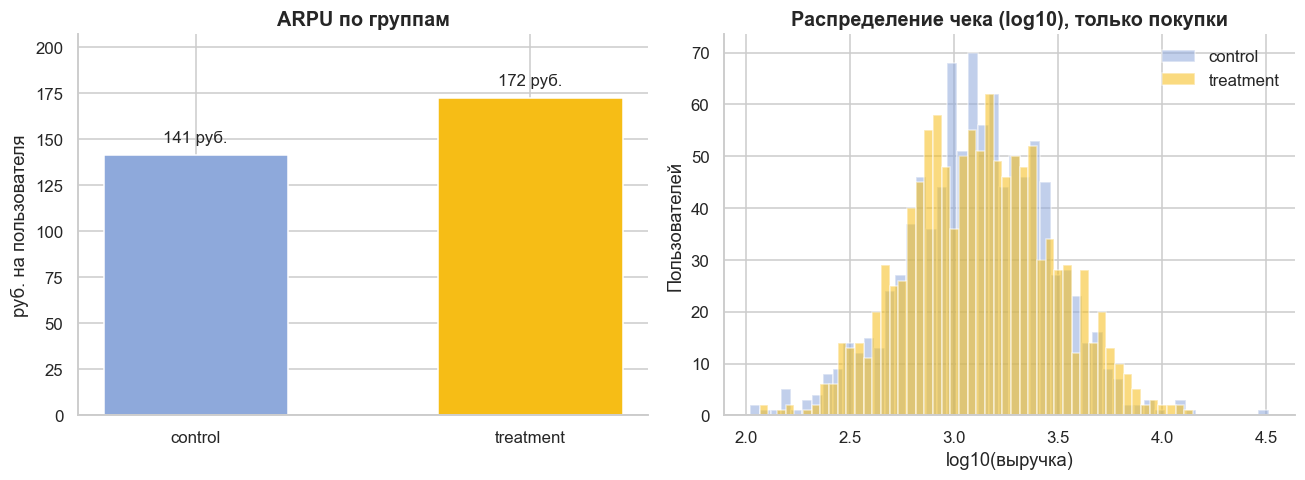

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

means = df.groupby('group')['revenue'].mean()
bars = axes[0].bar(means.index, means.values, color=['#8EA9DB', '#F6BD16'], width=0.55)
axes[0].bar_label(bars, fmt='%.0f руб.', padding=6)
axes[0].set(title='ARPU по группам', ylabel='руб. на пользователя', xlabel='')
axes[0].set_ylim(0, means.max() * 1.2)

converted = df[df['converted'] == 1]
for group, color in (('control', '#8EA9DB'), ('treatment', '#F6BD16')):
    subset = converted.loc[converted['group'] == group, 'revenue']
    axes[1].hist(np.log10(subset), bins=50, alpha=0.55, label=group, color=color)
axes[1].set(title='Распределение чека (log10), только покупки', xlabel='log10(выручка)', ylabel='Пользователей')
axes[1].legend(frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

ARPU вырос на 21.8 % (141.4 → 172.2 ₽), но большая часть прироста — это рост конверсии: покупателей стало больше, а значит и выручки на всю аудиторию. Среди тех, кто уже покупал, чек вырос на 3.3 % — это отдельный, более слабый эффект.

Распределение выручки сильно скошено: у большинства пользователей ноль, а редкие крупные чеки тянут среднее. Поэтому Манн—Уитни (сдвиг распределения) и бутстрэп-интервал для средних нужны вместе: тест говорит, что распределения различаются, а интервал — насколько неуверенны мы в размере эффекта.

## 5. Guardrail: доля возвратов

In [10]:
refund = df.groupby('group')['refunded'].mean()
r_c, r_t = refund['control'], refund['treatment']
n = df.groupby('group')['refunded'].size()
se_r = np.sqrt(r_c * (1 - r_c) / n['control'] + r_t * (1 - r_t) / n['treatment'])
diff_r = r_t - r_c

MARGIN = 0.005  # допустимый рост 0.5 п.п.
z_ni = (diff_r - MARGIN) / se_r
p_ni = stats.norm.cdf(z_ni)

print(f'возвраты: control {r_c:.2%}, treatment {r_t:.2%}, разница {diff_r * 100:+.2f} п.п.')
print(f'граница неинфериорности: +{MARGIN:.1%}')
print(f'z = {z_ni:.2f}, p = {p_ni:.3f}')

возвраты: control 2.09%, treatment 1.94%, разница -0.15 п.п.
граница неинфериорности: +0.5%
z = -3.61, p = 0.000


Guardrail пройден: доля возвратов не выросла (2.09 % → 1.94 %), верхняя граница допустимого роста 0.5 п.п. не превышена. Тест односторонний, потому что нас интересует только ухудшение.

## 6. Сегменты по устройству

In [11]:
segments = (df.groupby(['device', 'group'])['converted']
            .agg(users='size', conversion='mean').reset_index())
pivot = segments.pivot(index='device', columns='group', values=['users', 'conversion'])
display(pivot.round(4))

rows = []
for device, subset in df.groupby('device'):
    c = subset[subset['group'] == 'control']['converted']
    t = subset[subset['group'] == 'treatment']['converted']
    d = t.mean() - c.mean()
    se_d = np.sqrt(c.mean() * (1 - c.mean()) / len(c) + t.mean() * (1 - t.mean()) / len(t))
    z = d / se_d
    rows.append({'device': device,
                 'control': c.mean(), 'treatment': t.mean(),
                 'diff_pp': d * 100, 'ci_low': (d - z_alpha * se_d) * 100,
                 'ci_high': (d + z_alpha * se_d) * 100,
                 'p_value': 2 * (1 - stats.norm.cdf(abs(z))),
                 'se': se_d})
result = pd.DataFrame(rows)
display(result.round(4))

users            conversion          
group      control  treatment    control treatment
device                                            
desktop 4,695.0000 4,631.0000     0.0801    0.0881
mobile  7,605.0000 7,669.0000     0.0799    0.0981

,device,control,treatment,diff_pp,ci_low,ci_high,p_value,se
0,desktop,0.0801,0.0881,0.8017,-0.3249,1.9283,0.1631,0.0057
1,mobile,0.0799,0.0981,1.8110,0.9084,2.7135,0.0001,0.0046


In [12]:
# поправка Холма на два сравнения
result = result.sort_values('p_value').reset_index(drop=True)
m = len(result)
result['p_holm'] = [(m - i) * p for i, p in enumerate(result['p_value'])]
result['p_holm'] = result['p_holm'].cummax().clip(upper=1)
display(result[['device', 'diff_pp', 'p_value', 'p_holm']].round(4))

# тест на различие эффектов между сегментами
mobile = result.set_index('device').loc['mobile']
desktop = result.set_index('device').loc['desktop']
diff_prop = (mobile['treatment'] - mobile['control']) - (desktop['treatment'] - desktop['control'])
z_interaction = diff_prop / np.sqrt(mobile['se'] ** 2 + desktop['se'] ** 2)
p_interaction = 2 * (1 - stats.norm.cdf(abs(z_interaction)))
print(f'различие эффектов mobile и desktop: {diff_prop * 100:+.2f} п.п., '
      f'z = {z_interaction:.2f}, p = {p_interaction:.3f}')

,device,diff_pp,p_value,p_holm
0,mobile,1.8110,0.0001,0.0002
1,desktop,0.8017,0.1631,0.1631


различие эффектов mobile и desktop: +1.01 п.п., z = 1.37, p = 0.171


На мобильных прирост 1.81 п.п. (p = 0.0001) — значим и после поправки Холма. На десктопе 0.80 п.п. (p = 0.16) — в пределах случайного разброса. При этом формальный тест на различие эффектов даёт p ≈ 0.17: утверждать «эффект только на мобильных» нельзя, разница между сегментами статистически не доказана. Для десктопа нужна отдельная выборка.

## 7. Достигнутая чувствительность

In [13]:
se_observed = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
mde_observed = (z_alpha + z_beta) * se_observed
print(f'фактический MDE при текущем размере выборки: {mde_observed * 100:.2f} п.п.')
print(f'наблюдаемый эффект: {diff * 100:.2f} п.п. — в {diff / mde_observed:.1f} раза больше MDE')

фактический MDE при текущем размере выборки: 1.01 п.п.
наблюдаемый эффект: 1.43 п.п. — в 1.4 раза больше MDE


## 8. Ограничения

- Данные синтетические: эффект заложен генератором, поэтому совпадение оценок с «истиной» — проверка методики, а не открытие.
- Нет данных о показах и воронке: невозможно проверить, где именно выросла конверсия (просмотр → корзина → оплата).
- Нет истории пользователей: неизвестно, были ли покупки раньше, поэтому нельзя отделить новых клиентов от повторных.
- Один эксперимент и один период: нет проверки на устойчивость эффекта во времени.
- ARPU сильно скошен: среднее чувствительно к десятку крупных чеков, поэтому интервал шире, чем хотелось бы.

## 9. Итог и решение

- SRM не обнаружен: разделение 50/50 выдержано, в том числе внутри устройств.
- Первичная метрика выросла на 1.4 п.п. (≈18 %), 95 % ДИ не включает ноль — эффект есть.
- ARPU вырос на 21.8 %: в основном за счёт конверсии, а чек у покупателей — на 3.3 %.
- Guardrail по возвратам пройден: рост в пределах допустимых 0.5 п.п.
- Эффект больше на мобильных (+1.81 п.п.), на десктопе он не значим (+0.80 п.п.); при этом различие между сегментами статистически не доказано (p ≈ 0.17).

**Решение:** раскатывать вариант на 100 % аудитории, продолжив следить за возвратами; отдельно проверить десктоп на большей выборке, если он важен для бизнеса.